<a href="https://colab.research.google.com/github/Arka13/GoogleColabRepo/blob/main/20261024_upgrad_week_5_final_c2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clustering Learners' Queries: From a Lecture Chat Log to Themes

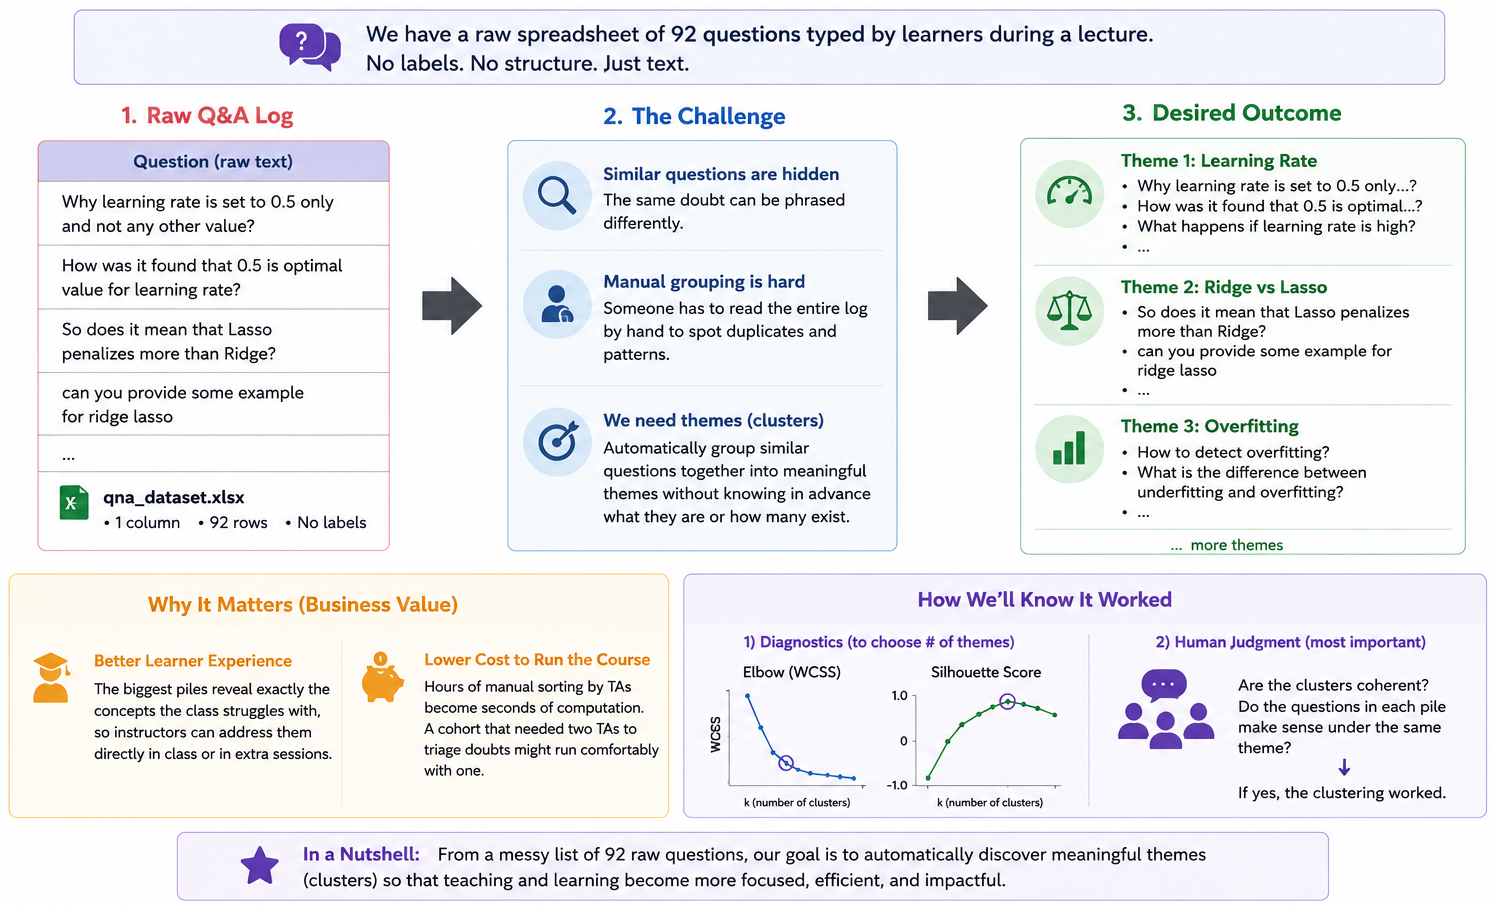

**The journey:**

| Step | What we do | Why |
|---|---|---|
| **1. Load & inspect** | Read the questions, drop exact duplicates | Understand the raw data before modelling |
| **2. Embed** | Turn each question into a 384-D meaning vector (`all-MiniLM-L6-v2`) | Cluster by **meaning**, not shared words |
| **3. Curse of dimensionality** | See why raw 384-D distances stop being informative | Motivate reducing the dimensions first |
| **4. PCA** | Compress to the components holding ~90% of the variance | Cut noise and restore trustworthy distances |
| **5. Choose `k`** | K-Means guided by the **elbow** and **silhouette** | Pick the number of themes in a principled way |
| **6. Reveal themes** | Fit the final K-Means and print each question group | The payoff: a grouped, answer-once sheet |

---


## Setup



In [ ]:
%pip install -q sentence-transformers openpyxl

import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# A consistent, readable plotting style
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

RANDOM_STATE = 42   # fixing the seed makes every run reproducible

## 1: Load & inspect the data

Before modelling anything, always *look* at the raw data: how many rows, are there
duplicates, how long are the questions?


In [ ]:
df = pd.read_excel("qna_dataset.xlsx")

df = df.drop_duplicates().reset_index(drop=True)
questions = df["Question"].tolist() # converting pandas series to list

print(f"Number of unique questions : {len(questions)}")
print(f"Average length (characters): {int(np.mean([len(q) for q in questions]))}")
print(f"Shortest / longest         : {min(map(len, questions))} / {max(map(len, questions))} chars\n")

print("A few examples:")
for q in questions[:5]:
    print("  •", q)

Number of unique questions : 92
Average length (characters): 93
Shortest / longest         : 14 / 372 chars

A few examples:
  • Hello Sir, I ddin't get why there are only 2 Inputs, x1 and x2, not more, did the research identified that
  • I didn't understand the difference in calculation between the AND and OR logic? The calculation to arrive at the answer was same. Could you elaborate a bit?
  • Sir, how sigma ri * wi related to vector products in real life significance?
  • Does synapses carry the weights?
  • Is it necessary to remember all these formulas or just concept is enough?


## 2: From words to vectors — sentence embeddings

A computer cannot cluster text directly clustering works on **numbers**. So our
first job is to turn each question into a vector (a list of numbers). The *way* we do
this decides whether the whole pipeline succeeds or fails.


A **sentence embedding model** is a neural network trained on billions of sentences to
map text into a fixed length vector of real numbers (here, **384 numbers per
question**) such that *sentences with similar meaning land near each other* even when
they use completely different words. It has effectively learned that "learning rate"
and "step size" point in almost the same direction.




In [ ]:
# Load the pre-trained model
model = SentenceTransformer("all-MiniLM-L6-v2")

# Encode every question. normalize_embeddings=True scales each vector to length 1,
embeddings = model.encode(
    questions,
    normalize_embeddings=True,
    show_progress_bar=True,
)

print("\nEmbedding matrix shape:", embeddings.shape, " (questions × dimensions)")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/3 [00:00<?, ?it/s]


Embedding matrix shape: (92, 384)  (questions × dimensions)


## 3: The curse of dimensionality — why distance loses meaning in high dimensions

We now hold a **384 dimensional** vector for each question. Our clustering algorithm,
K-Means, works by measuring **distances** between points. So we have to confront an
uncomfortable fact of high dimensional geometry.

### The intuition

In everyday 2D or 3D space, "near" and "far" are meaningful: your closest neighbour is
clearly closer than the person across the street. But as the number of dimensions grows,
something strange happens **every point drifts to roughly the same distance from every
other point.** The gap between your *nearest* and *farthest* neighbour shrinks until it
is almost nothing.

Here is one way to feel why. Two random points are "close" only if they happen to be
close **in every single dimension at once**. Adding a dimension is another independent
chance for them to differ. With hundreds of dimensions, essentially every pair differs
somewhere, so all pairwise distances pile up into a narrow band.
### Why it breaks clustering

A useful way to measure the problem is the **relative contrast**:

$$\text{contrast} = \frac{d_{\max}}{d_{\min}} - 1$$

where $d_{\min}$ and $d_{\max}$ are the distances from one point to its nearest and
farthest neighbours. When contrast is large, "nearest" is meaningfully nearer than
"farthest," and distance based methods work well. **As dimensions grow, contrast
collapses toward 0**.


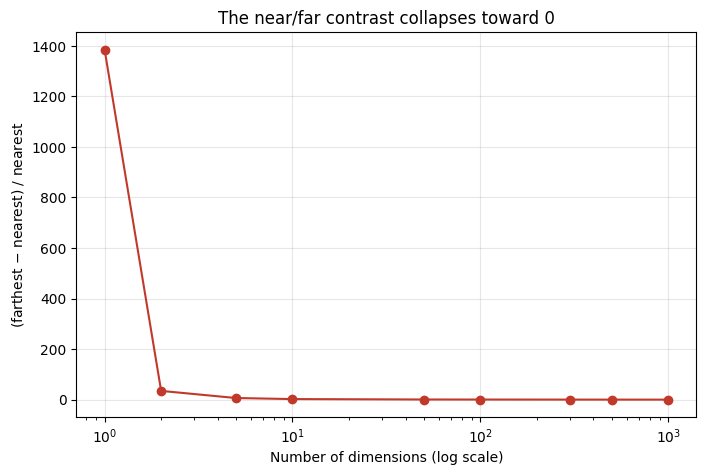

In [ ]:
rng = np.random.default_rng(0)
dims = [1, 2, 5, 10, 50, 100, 300, 500, 1000]
contrast = []
for d in dims:
    pts = rng.random((500, d))                 # 500 random points in d dimensions
    p0 = pts[0]
    dist = np.linalg.norm(pts[1:] - p0, axis=1)
    contrast.append((dist.max() - dist.min()) / dist.min())

plt.figure()
plt.plot(dims, contrast, "o-", color="#c0392b")
plt.xscale("log")
plt.xlabel("Number of dimensions (log scale)")
plt.ylabel(r"(farthest $-$ nearest) / nearest")
plt.title("The near/far contrast collapses toward 0")
plt.show()



## 4: PCA — compressing meaning into a few dimensions

Principal Component Analysis (PCA) reduces the dimensionality of the data while preserving as much variance as possible. It computes a new set of **orthogonal (perpendicular) principal components**, ordered by the amount of variance they explain. The first component captures the highest variance, the second captures the next highest while remaining orthogonal to the first, and so on.

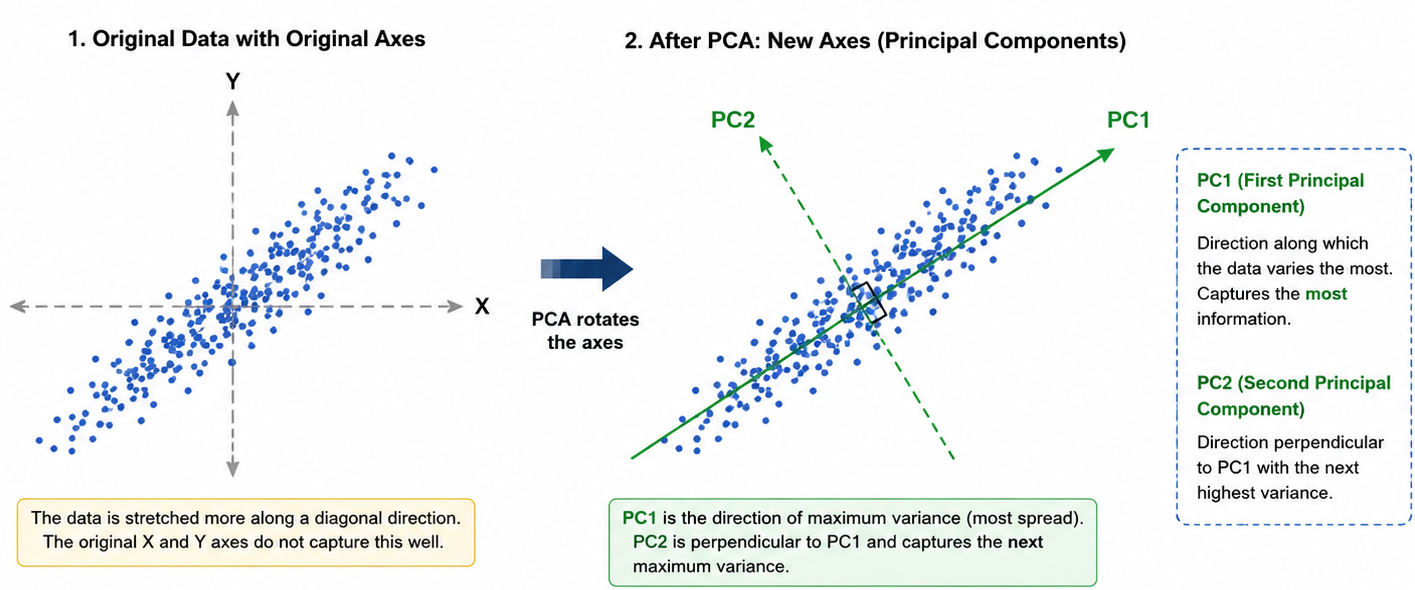
Instead of using all 384 dimensions, we retain only the first few principal components that explain most of the variance (typically around **90%**). This removes redundant and low-variance information, reduces noise, and makes Euclidean distances more meaningful, leading to better K-Means clustering.

Components needed to retain 90% of the variance: 49
(down from the original 384 dimensions)


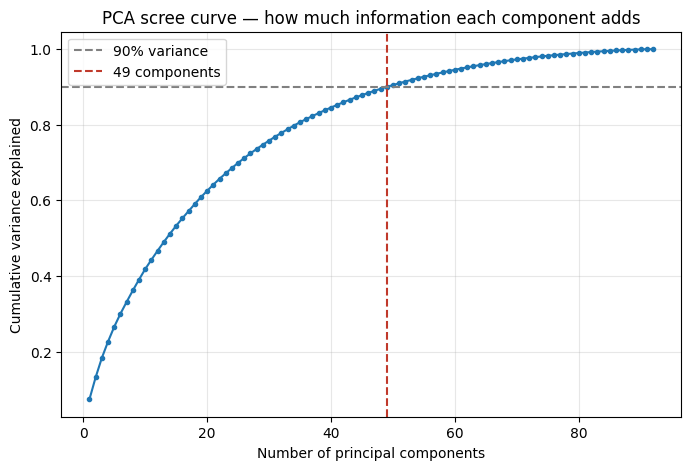

In [ ]:
# Fit PCA
pca_full = PCA().fit(embeddings)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
# Smallest number of components that retains at least 90% of the variance.
n_components = int(np.argmax(cumvar >= 0.90)) + 1
print(f"Components needed to retain 90% of the variance: {n_components}")
print(f"(down from the original {embeddings.shape[1]} dimensions)")

plt.figure()
plt.plot(range(1, len(cumvar) + 1), cumvar, ".-")
plt.axhline(0.90, color="grey", ls="--", label="90% variance")
plt.axvline(n_components, color="#c0392b", ls="--", label=f"{n_components} components")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative variance explained")
plt.title("PCA scree curve — how much information each component adds")
plt.legend()
plt.show()

In [ ]:
pca = PCA(n_components=0.90)
X = pca.fit_transform(embeddings)



print(f"Reduced representation shape: {X.shape}  (questions × components)")
print(f"Variance retained: {pca.explained_variance_ratio_.sum():.1%}")

Reduced representation shape: (92, 49)  (questions × components)
Variance retained: 90.0%


## 5: Choosing the number of themes — K-Means, the elbow, and silhouette

We are finally ready to cluster. Our tool is **K-Means**, and the central challenge is
deciding **how many clusters k**?

### How does K-means work?
1. Initialize centroids: Randomly select K data points from the dataset to serve as the initial centroids.

2. ***E Step*** Assign data points to clusters: Calculate the distance between each data point and each centroid. Assign each data point to the cluster whose centroid is closest to it.

3. ***M Step*** Update centroids: Recalculate the centroids of the clusters based on the mean of the data points assigned to each cluster.

4. Repeat steps 2 and 3: Iterate the assignment and update steps until convergence. Convergence occurs when the centroids no longer change significantly or a maximum number of iterations is reached.

5. Finalize clusters: Once convergence is achieved, the algorithm stops, and the final clusters are determined.

---

### Two ways for picking `k`

K-Means will happily split the data into whatever `k` you request, so we need a
principled way to choose. We use **two complementary diagnostics**:

### The elbow method (WCSS)  

*WCSS* Within Cluster Sum of Squares, also called the
model's **inertia** measures how tightly packed each cluster is by summing the squared
distance from every point to its own centre.


$$
\mathrm{WCSS}=\sum_{k=1}^{K}\sum_{\mathbf{x}_i\in C_k}\left\|\mathbf{x}_i-\boldsymbol{\mu}_k\right\|^2
$$

where:

- $K$ is the number of clusters.
- $C_k$ is the set of data points assigned to cluster $k$.
- $\mathbf{x}_i$ is the $i$-th data point.
- $\boldsymbol{\mu}_k$ is the centroid of cluster $k$.
- $\left\|\mathbf{x}_i-\boldsymbol{\mu}_k\right\|^2$ is the squared Euclidean distance between a data point and its assigned centroid.

A lower **WCSS** indicates that data points are more tightly grouped around their cluster centroids, resulting in more compact clusters.

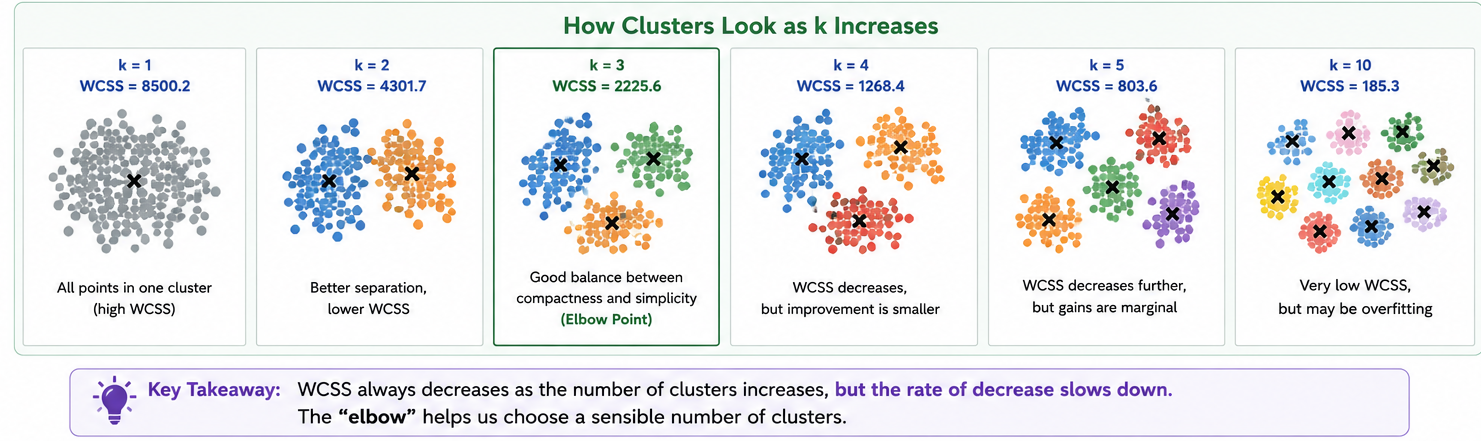

 More clusters always means tighter clusters,
so WCSS **always decreases** as `k` grows; it never has a maximum. Instead we look for the
**"elbow"**: the `k` after which adding more clusters gives only tiny improvements. That
bend marks the point of diminishing returns.

---




### Silhouette Score

The **Silhouette Score** for a data point is defined as:

$$
s(i)=\frac{b(i)-a(i)}{\max\{a(i),\,b(i)\}}
$$

where:

- $a(i)$ is the average distance from point $i$ to all other points in the **same cluster** (intra-cluster distance).
- $b(i)$ is the smallest average distance from point $i$ to all points in the **nearest neighboring cluster** (nearest-cluster distance).

The overall **Silhouette Score** is the average of the individual scores:

$$
\text{Silhouette Score}=\frac{1}{N}\sum_{i=1}^{N}s(i)
$$

where $N$ is the total number of data points.

The score ranges from **-1 to 1**:
- **+1:** Well-separated, compact clusters.
- **0:** Overlapping clusters or points near cluster boundaries.
- **-1:** Points are likely assigned to the wrong cluster.



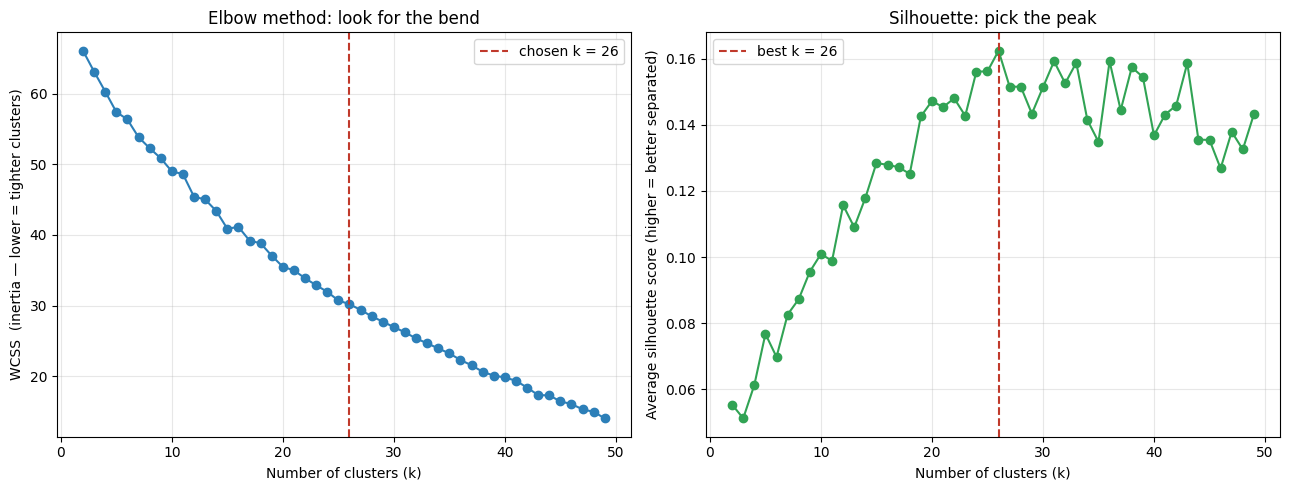

In [ ]:
K_RANGE = range(2, 50)

wcss = []           # within cluster sum of squares (inertia) for the elbow method
sil_scores = []     # average silhouette score

for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X)
    wcss.append(km.inertia_)
    sil_scores.append(silhouette_score(X, km.labels_))

best_k = list(K_RANGE)[int(np.argmax(sil_scores))]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(list(K_RANGE), wcss, "o-", color="#2c7fb8")
ax1.axvline(best_k, color="#c0392b", ls="--", label=f"chosen k = {best_k}")
ax1.set_xlabel("Number of clusters (k)")
ax1.set_ylabel("WCSS  (inertia — lower = tighter clusters)")
ax1.set_title("Elbow method: look for the bend")
ax1.legend()

ax2.plot(list(K_RANGE), sil_scores, "o-", color="#31a354")
ax2.axvline(best_k, color="#c0392b", ls="--", label=f"best k = {best_k}")
ax2.set_xlabel("Number of clusters (k)")
ax2.set_ylabel("Average silhouette score (higher = better separated)")
ax2.set_title("Silhouette: pick the peak")
ax2.legend()

plt.tight_layout()
plt.show()

## 6: The question groups

We fit K-Means one last time at our chosen `k` and inspect the result. For each cluster
we show:

- its **size** (how many questions it captured)
- and the full list of member questions.


In [ ]:
final_km = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10).fit(X)
labels = final_km.labels_

theme_counter = 1
for c in range(best_k):
    idx = np.where(labels == c)[0] # why [0]: returns a tuple ([, , ,]) to get list
    group = [questions[i] for i in idx]

    if len(idx) > 2: # only showing clusters with greater then 2 questions
     print("=" * 78)
     print(f"THEME {theme_counter}   ({len(idx)} questions)")
     theme_counter += 1
     print("-" * 78)
     for q in group:
        print("  •", q)
    print()




THEME 1   (5 questions)
------------------------------------------------------------------------------
  • how did Linear model shows 100% with no penalty for training ?
  • Why learning rate is set to 0.5 only and not any other value?
  • How was it found that 0.5 is optimal value for learning rate?
  • We are only using learning rate in stochastic GD and not in Batch. What is the role of learning rate and when do we use it?
  • What is the role of learning rate in models?

THEME 2   (10 questions)
------------------------------------------------------------------------------
  • So does it mean that Lasso penalizes more than Ridge?
  • can you provide some example for ridge lasso
  • Can we use Lasso and Ridge for every machine learning problem?
  • what does "give sparsity" yes and no for Lasso and Ridge mean?
  • How do we choose between Ridge and Lasso in the current use case, since both are now generalizable?
  • in place of correlation drop can we use variable clustring to sele

## Summary

We built a complete unsupervised pipeline that turns a chaotic list of student questions
into a small set of themes:

1. **Embeddings** converted each question into a 384 dimensional meaning vector, so that
   paraphrases sit close together even when they share no words something bag-of-words
   could never do.
2. The **curse of dimensionality** warned us that raw 384-D distances are almost
   meaningless, because in high dimensions every point is roughly equidistant from every
   other.
3. **PCA** compressed the vectors down to the handful of components that carry ~90% of the
   information, removing noise and restoring trustworthy distances.
4. **K-Means**, guided by the **elbow (WCSS)** and **silhouette** diagnostics, discovered a
   sensible number of themes and assigned every question to one.

---



### Take Home Exercises

1. **Name the themes.** Read each printed cluster and give it a human label
   (e.g. *"Regularisation: Ridge vs Lasso"*, *"Learning rate & convergence"*).
2. **Change the PCA budget.** Re-run Section 4 keeping **95%** variance instead of 90%
   (change the `0.90` threshold). Does `best_k` change? Do the clusters get cleaner or
   noisier?
3. **Force a different `k`.** Set `best_k = 6` by hand before Section 6 and compare the
   groups to the data-driven choice. Which is more useful to an instructor?
4. **Skip PCA.** Cluster the raw `embeddings` directly (feed `embeddings` to `KMeans`
   instead of `X`) and compare silhouette scores. This lets you *measure* the curse of
   dimensionality from Section 3 rather than just read about it.

Fill in the blank to get started on exercise 4:


In [ ]:
'''# EXERCISE 4 cluster WITHOUT PCA and compare separation quality.
# Fill in the blanks marked ____ and run.

k_demo = best_k
km_raw  = KMeans(n_clusters=k_demo, random_state=RANDOM_STATE, n_init=10).fit(____)   # hint: the 384 D matrix
km_pca  = KMeans(n_clusters=k_demo, random_state=RANDOM_STATE, n_init=10).fit(X)

sil_raw = silhouette_score(________, km_raw.labels_)   # same matrix you clustered on
sil_pca = silhouette_score(X,        km_pca.labels_)

print(f"Silhouette on raw 384-D embeddings : {sil_raw:.3f}")
print(f"Silhouette after PCA               : {sil_pca:.3f}")
print("Which representation separates the themes better, and why?")'''

'# EXERCISE 4 cluster WITHOUT PCA and compare separation quality.\n# Fill in the blanks marked ____ and run.\n\nk_demo = best_k\nkm_raw  = KMeans(n_clusters=k_demo, random_state=RANDOM_STATE, n_init=10).fit(____)   # hint: the 384 D matrix\nkm_pca  = KMeans(n_clusters=k_demo, random_state=RANDOM_STATE, n_init=10).fit(X)\n\nsil_raw = silhouette_score(________, km_raw.labels_)   # same matrix you clustered on\nsil_pca = silhouette_score(X,        km_pca.labels_)\n\nprint(f"Silhouette on raw 384-D embeddings : {sil_raw:.3f}")\nprint(f"Silhouette after PCA               : {sil_pca:.3f}")\nprint("Which representation separates the themes better, and why?")'


### Food for Thought: Does embeddigs actually help us in capturing closeness?

For two normalised vectors, **cosine similarity** ranges from **1** (identical
direction / meaning) down through **0** (unrelated) to **-1** (opposite). We will sanity
check the embeddings with it right after computing them.


Let's verify. We pick a pair of questions we *know* are about the same idea, and a pair
we know are unrelated, and compare their cosine similarities. Because the vectors are
normalised, cosine similarity is simply their dot product.


In [ ]:
'''def show_similarity(i, j):
    sim = float(np.dot(embeddings[i], embeddings[j]))  # cosine sim for unit vectors
    print(f"cos = {sim:+.2f}")
    print("   Q1:", questions[i][:80])
    print("   Q2:", questions[j][:80], "\n")

lr   = [k for k, q in enumerate(questions) if "learning rate" in q.lower()]
misc = [k for k, q in enumerate(questions) if "reading material" in q.lower()]

print("SIMILAR pair (both about the learning rate):")
show_similarity(lr[0], lr[1])

print("UNRELATED pair (learning rate vs. sharing study material):")
show_similarity(lr[0], misc[0])'''

'def show_similarity(i, j):\n    sim = float(np.dot(embeddings[i], embeddings[j]))  # cosine sim for unit vectors\n    print(f"cos = {sim:+.2f}")\n    print("   Q1:", questions[i][:80])\n    print("   Q2:", questions[j][:80], "\n")\n\nlr   = [k for k, q in enumerate(questions) if "learning rate" in q.lower()]\nmisc = [k for k, q in enumerate(questions) if "reading material" in q.lower()]\n\nprint("SIMILAR pair (both about the learning rate):")\nshow_similarity(lr[0], lr[1])\n\nprint("UNRELATED pair (learning rate vs. sharing study material):")\nshow_similarity(lr[0], misc[0])'